In [2]:
# 06_model_evaluation.ipynb

# === CELL 1: Setup ===
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, auc, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

OUTPUT_DIR = Path("./data/processed")
MODEL_DIR = Path("./models")
RESULT_DIR = Path("./results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

IMG_SIZE = 224


Device: cuda


In [3]:
# === CELL 2: Transforms ===
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


# === CELL 3: Inlined Dataset Class ===
EXCLUDE_COLS = {"ID", "has_cad", "max_stenosis", "num_diseased_vessels"}

def feature_columns(clinical_df):
    return [c for c in clinical_df.columns if c not in EXCLUDE_COLS]


class AngioCADDataset(Dataset):
    def __init__(self, patient_df, frames_df, clinical_df, transform=None,
                 aggregate="mean"):
        self.patients = patient_df.reset_index(drop=True)
        self.frames = frames_df
        self.clinical = clinical_df.set_index("ID")
        self.transform = transform
        self.aggregate = aggregate
        self.feature_cols = feature_columns(clinical_df)

    def __len__(self):
        return len(self.patients)

    def _load_frames(self, pid):
        subset = self.frames[self.frames["ID"] == str(int(pid))]
        tensors = []
        for path in subset["path"].tolist():
            try:
                img = Image.open(path).convert("RGB")
                tensors.append(self.transform(img) if self.transform
                               else transforms.ToTensor()(img))
            except Exception:
                continue
        return tensors

    def _aggregate(self, tensors):
        if not tensors:
            return torch.zeros(3, IMG_SIZE, IMG_SIZE)
        stack = torch.stack(tensors)
        if self.aggregate == "max":
            return stack.max(dim=0).values
        return stack.mean(dim=0)

    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        pid = int(row["ID"])
        img = self._aggregate(self._load_frames(pid))
        clinical = self.clinical.loc[pid, self.feature_cols].values.astype(np.float32)
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return img, torch.from_numpy(clinical), label

In [5]:
# === CELL 4: Inlined Model Classes ===
class ImageEncoder(nn.Module):
    def __init__(self, out_dim=256, pretrained=False):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.resnet18(weights=weights)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.proj = nn.Sequential(
            nn.Linear(feat_dim, out_dim), nn.ReLU(inplace=True), nn.Dropout(0.3),
        )
    def forward(self, x):
        return self.proj(self.backbone(x))


class ClinicalEncoder(nn.Module):
    def __init__(self, in_dim, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128), nn.BatchNorm1d(128),
            nn.ReLU(inplace=True), nn.Dropout(0.3),
            nn.Linear(128, out_dim), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)


class FusionModel(nn.Module):
    def __init__(self, clinical_dim, num_classes=2):
        super().__init__()
        self.img_enc = ImageEncoder(out_dim=256)
        self.clin_enc = ClinicalEncoder(clinical_dim, out_dim=128)
        self.classifier = nn.Sequential(
            nn.Linear(256 + 128, 128), nn.ReLU(inplace=True), nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )
    def forward(self, image, clinical):
        return self.classifier(torch.cat(
            [self.img_enc(image), self.clin_enc(clinical)], dim=1
        ))

In [6]:
# === CELL 5: Load Test Data + Model ===
clinical_df = pd.read_csv(OUTPUT_DIR / "clinical_features_merged.csv")
frames_df = pd.read_csv(OUTPUT_DIR / "frames_index.csv")
diagnosis_df = pd.read_csv(OUTPUT_DIR / "diagnosis_labels.csv")
frames_df["ID"] = frames_df["ID"].astype(str)

with open(OUTPUT_DIR / "splits.json") as f:
    splits = json.load(f)

test_df = clinical_df[clinical_df["ID"].isin(splits["test"])]
test_ds = AngioCADDataset(test_df, frames_df, clinical_df, transform=eval_tfms)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)

checkpoint = torch.load(MODEL_DIR / "best_fusion_model.pt", map_location=DEVICE)
clinical_dim = checkpoint["clinical_dim"]
model = FusionModel(clinical_dim=clinical_dim).to(DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()

print(f"Loaded checkpoint: Epoch {checkpoint['epoch']}, "
      f"Best Val AUC {checkpoint['best_auc']:.4f}")
print(f"Test patients: {len(test_ds)}")

Loaded checkpoint: Epoch 17, Best Val AUC 0.8861
Test patients: 76


In [7]:
# === CELL 6: Predictions ===
y_true, y_pred, y_prob = [], [], []
with torch.no_grad():
    for image, clinical, y in test_loader:
        image = image.to(DEVICE)
        clinical = clinical.to(DEVICE)
        logits = model(image, clinical)
        prob = torch.softmax(logits, dim=1)[:, 1]
        y_true.append(y.numpy())
        y_pred.append(logits.argmax(dim=1).cpu().numpy())
        y_prob.append(prob.cpu().numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
y_prob = np.concatenate(y_prob)

In [8]:
# === CELL 7: Classification Report ===
print("=" * 68)
print("TEST CLASSIFICATION REPORT")
print("=" * 68)
print(classification_report(y_true, y_pred,
                            target_names=["No CAD", "CAD"], digits=4))

metrics = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "auc": float(roc_auc_score(y_true, y_prob)),
    "f1": float(f1_score(y_true, y_pred)),
    "precision": float(precision_score(y_true, y_pred, zero_division=0)),
    "recall": float(recall_score(y_true, y_pred, zero_division=0)),
}
print("\nKey Metrics:")
for k, v in metrics.items():
    print(f"  {k:10s}: {v:.4f}")

TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      No CAD     0.4800    0.7500    0.5854        16
         CAD     0.9216    0.7833    0.8468        60

    accuracy                         0.7763        76
   macro avg     0.7008    0.7667    0.7161        76
weighted avg     0.8286    0.7763    0.7918        76


Key Metrics:
  accuracy  : 0.7763
  auc       : 0.8510
  f1        : 0.8468
  precision : 0.9216
  recall    : 0.7833


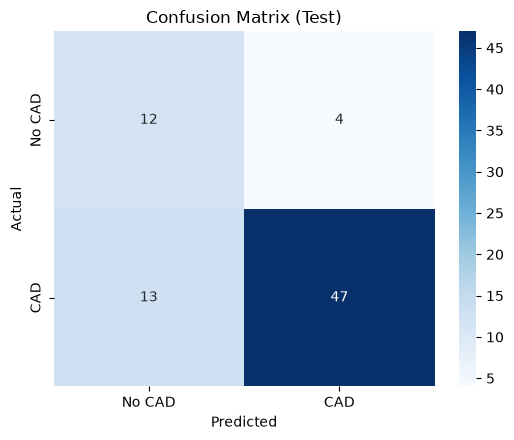


Sensitivity: 0.7833
Specificity: 0.7500


In [9]:
# === CELL 8: Confusion Matrix ===
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No CAD", "CAD"], yticklabels=["No CAD", "CAD"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Test)")
plt.tight_layout()
plt.savefig(RESULT_DIR / "confusion_matrix.png", dpi=200)
plt.show()

tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
specificity = tn / (tn + fp) if (tn + fp) else 0.0
print(f"\nSensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

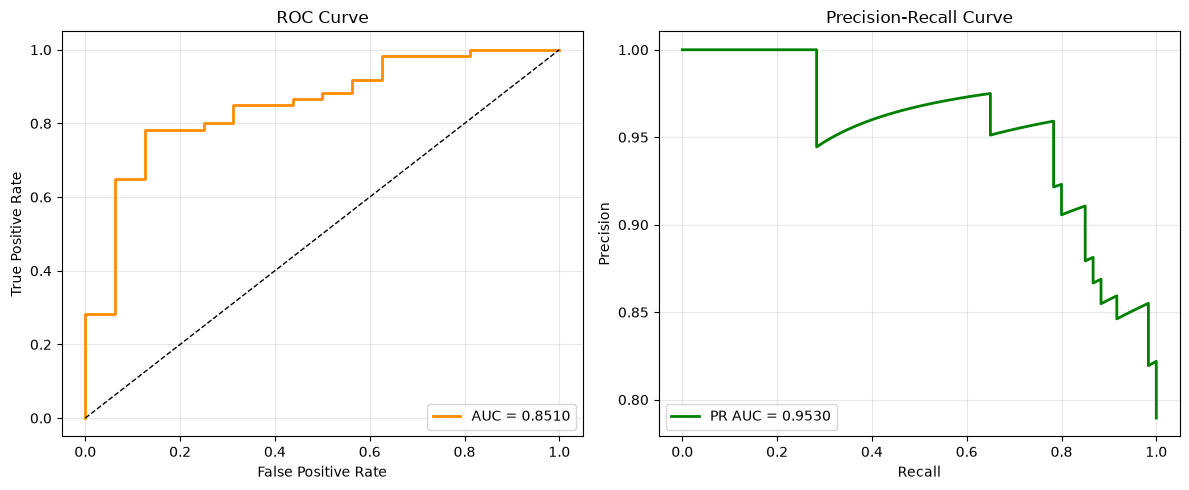

In [10]:
# === CELL 9: ROC + PR Curves ===
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_value = auc(fpr, tpr)

precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_prob)
pr_value = auc(recall_curve, precision_curve)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, color="darkorange", lw=2, label=f"AUC = {roc_value:.4f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

axes[1].plot(recall_curve, precision_curve, color="green", lw=2,
             label=f"PR AUC = {pr_value:.4f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(loc="lower left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RESULT_DIR / "roc_pr_curves.png", dpi=200)
plt.show()

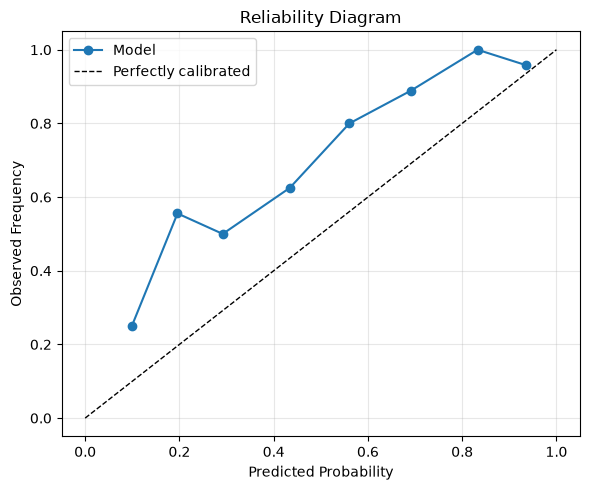

In [11]:
# === CELL 10: Calibration Curve ===
prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=8)
plt.figure(figsize=(6, 5))
plt.plot(prob_pred, prob_true, marker="o", label="Model")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Perfectly calibrated")
plt.xlabel("Predicted Probability")
plt.ylabel("Observed Frequency")
plt.title("Reliability Diagram")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "calibration_curve.png", dpi=200)
plt.show()

In [12]:

# === CELL 11: Threshold Tuning ===
print("\n" + "=" * 68)
print("THRESHOLD TUNING (Finding best F1)")
print("=" * 68)
best_thresh, best_f1_thresh = 0.5, 0.0
results = []
for t in np.arange(0.10, 0.90, 0.05):
    preds_t = (y_prob > t).astype(int)
    f1_t = f1_score(y_true, preds_t, zero_division=0)
    rec_t = recall_score(y_true, preds_t, zero_division=0)
    prec_t = precision_score(y_true, preds_t, zero_division=0)
    results.append({"threshold": round(t, 2), "F1": f1_t,
                    "Recall": rec_t, "Precision": prec_t})
    if f1_t > best_f1_thresh:
        best_f1_thresh = f1_t
        best_thresh = t

thresh_df = pd.DataFrame(results).round(4)
print(thresh_df.to_string(index=False))
print(f"\n🎯 Optimal threshold: {best_thresh:.2f}")
print(f"🎯 Best F1 at this threshold: {best_f1_thresh:.4f}")

# Apply optimal threshold
y_pred_opt = (y_prob > best_thresh).astype(int)
print("\n" + "=" * 68)
print(f"CLASSIFICATION REPORT @ threshold = {best_thresh:.2f}")
print("=" * 68)
print(classification_report(y_true, y_pred_opt,
                            target_names=["No CAD", "CAD"], digits=4))


THRESHOLD TUNING (Finding best F1)
 threshold     F1  Recall  Precision
      0.10 0.8955  1.0000     0.8108
      0.15 0.9147  0.9833     0.8551
      0.20 0.9062  0.9667     0.8529
      0.25 0.8780  0.9000     0.8571
      0.30 0.8667  0.8667     0.8667
      0.35 0.8739  0.8667     0.8814
      0.40 0.8644  0.8500     0.8793
      0.45 0.8596  0.8167     0.9074
      0.50 0.8468  0.7833     0.9216
      0.55 0.8519  0.7667     0.9583
      0.60 0.7723  0.6500     0.9512
      0.65 0.7723  0.6500     0.9512
      0.70 0.7292  0.5833     0.9722
      0.75 0.6739  0.5167     0.9688
      0.80 0.6593  0.5000     0.9677
      0.85 0.5977  0.4333     0.9630

🎯 Optimal threshold: 0.15
🎯 Best F1 at this threshold: 0.9147

CLASSIFICATION REPORT @ threshold = 0.15
              precision    recall  f1-score   support

      No CAD     0.8571    0.3750    0.5217        16
         CAD     0.8551    0.9833    0.9147        60

    accuracy                         0.8553        76
   macro avg

In [13]:

# === CELL 12: Subgroup Analysis ===
diagnosis_df["ID"] = diagnosis_df["ID"].astype(int)
test_ids = test_df["ID"].astype(int).tolist()
test_meta = diagnosis_df[diagnosis_df["ID"].isin(test_ids)].set_index("ID")

predictions = pd.DataFrame({
    "ID": test_ids, "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob,
})
predictions = predictions.merge(
    test_meta.reset_index()[["ID", "Diagnosis"]], on="ID", how="left"
)

subgroup_rows = []
for diagnosis, group in predictions.groupby("Diagnosis"):
    if len(group) < 5:
        continue
    subgroup_rows.append({
        "Diagnosis": diagnosis,
        "n": len(group),
        "AUC": roc_auc_score(group["y_true"], group["y_prob"])
               if group["y_true"].nunique() > 1 else np.nan,
        "Accuracy": accuracy_score(group["y_true"], group["y_pred"]),
        "F1": f1_score(group["y_true"], group["y_pred"], zero_division=0),
    })

subgroup_df = pd.DataFrame(subgroup_rows).round(4)
subgroup_df.to_csv(RESULT_DIR / "subgroup_analysis.csv", index=False)
print("\n" + "=" * 68)
print("SUBGROUP ANALYSIS BY DIAGNOSIS")
print("=" * 68)
print(subgroup_df.to_string(index=False))


SUBGROUP ANALYSIS BY DIAGNOSIS
Diagnosis  n    AUC  Accuracy     F1
       SA 25 0.9416    0.8000 0.7826
    STEMI 41 0.6667    0.8537 0.9211
       UA 10 0.3810    0.4000 0.5000


In [14]:
# === CELL 13: Save Everything ===
results = {
    "metrics": metrics,
    "roc_auc": float(roc_value),
    "pr_auc": float(pr_value),
    "sensitivity": float(sensitivity),
    "specificity": float(specificity),
    "confusion_matrix": cm.tolist(),
    "best_epoch": int(checkpoint["epoch"]),
    "best_val_auc": float(checkpoint["best_auc"]),
    "optimal_threshold": float(best_thresh),
    "optimal_f1": float(best_f1_thresh),
}
with open(RESULT_DIR / "test_results.json", "w") as f:
    json.dump(results, f, indent=2)

predictions.to_csv(RESULT_DIR / "test_predictions.csv", index=False)

print("\n" + "=" * 68)
print("SAVED RESULTS")
print("=" * 68)
print(f"✅ {RESULT_DIR / 'test_results.json'}")
print(f"✅ {RESULT_DIR / 'test_predictions.csv'}")
print(f"✅ {RESULT_DIR / 'subgroup_analysis.csv'}")
print(f"✅ {RESULT_DIR / 'confusion_matrix.png'}")
print(f"✅ {RESULT_DIR / 'roc_pr_curves.png'}")
print(f"✅ {RESULT_DIR / 'calibration_curve.png'}")


SAVED RESULTS
✅ results\test_results.json
✅ results\test_predictions.csv
✅ results\subgroup_analysis.csv
✅ results\confusion_matrix.png
✅ results\roc_pr_curves.png
✅ results\calibration_curve.png
